# 06b - Soil and Slope

**Owner:** Mostafa Elsherif
**Sources:** NASA SRTM (through Google Earth Engine) and FAO/IIASA GAEZ v5 - both in the challenge resources
**Output:** `data/processed/soil_slope_static.csv` - 560 rows, key = `cell_id`

## Why this notebook was added

`project_plan.md` (Step 4, Harmonization) asks for a table with one row per cell per month, including **slope** and **soil type**. When we checked the finished master table against that plan, those two columns were missing: notebook 05 gave us elevation, not slope, and no notebook covered soil.

Soil matters for a crop rotation tool more than almost anything else. Two fields with the same water and the same weather can still need different crops if one has salty soil or poor drainage. So we close the gap before the scoring step.

## What we measure

**Slope.** Our area is the flat Nile Delta, so we expect almost no slope. We measure it anyway, for two reasons: the plan asks for it, and "we checked and it is flat" is a stronger statement than "we assumed it is flat". We measure it **twice, from two independent sources**:

| Source | How |
|---|---|
| NASA SRTM, 30 m | slope of every 30 m pixel, computed in Earth Engine, then averaged per cell |
| GAEZ v5 `LR-SLC`, ~1 km | share of each cell's land in 10 slope classes, from 0-0.5% up to over 45% |

**Soil.** GAEZ v5 rates seven soil qualities on a scale from **0 (strongly limiting) to 1 (no limitation)**, for high-input farming (the same management level we use everywhere else):

| Column | GAEZ code | What it measures |
|---|---|---|
| `soil_overall` | SQ0 | the worst of all the qualities below |
| `soil_nutrients` | SQ1 | nutrient availability |
| `soil_nutrient_retention` | SQ2 | how well the soil holds added fertiliser |
| `soil_rooting` | SQ3 | room and conditions for roots |
| `soil_oxygen` | SQ4 | oxygen for roots - drainage and waterlogging |
| `soil_salinity` | SQ5 | salt and sodium |
| `soil_lime_gypsum` | SQ6 | excess lime or gypsum |
| `soil_workability` | SQ7 | how easy the soil is to till |

GAEZ also names the **single most limiting quality** in each place (`SQ-IDX`). That is the closest thing to a "soil type" label that is directly useful for a farmer: it says what the main soil problem is.

## How the classes are read

GAEZ stores soil quality as **classes 1 to 10**, each a band of 0.1 (class 1 = 0.0-0.1, class 10 = 0.9-1.0). Classes 11, 12 and 13 mean permafrost, not evaluated and water. We turn every pixel into the **middle of its band** (class 7 -> 0.65) before averaging, and set classes 11-13 to empty. Averaging the raw class numbers would also work for 1-10, but it would silently mix in 11-13 as if "water" were a soil better than the best soil.

The most-limiting-quality layer is a **category**, so for it we take the **most common value** in each cell, never an average.

In [11]:
%pip install rasterio pyproj scipy earthengine-api -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.transform import rowcol
from pyproj import Transformer
from scipy.stats import spearmanr

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent                      # works for everyone, not just one laptop
P   = REPO / "data" / "processed"
FIG = REPO / "figures"
FIG.mkdir(exist_ok=True)

GAEZ_BASE = os.environ.get("GAEZ_BASE",
    "https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET")

W, S, E, N = 30.70, 31.05, 30.91, 31.30
PAD = 0.05
assert 31 <= S < N < 32 and 30 <= W < E < 31, "lat/lon swapped"

grid = pd.read_csv(P / "grid_1km.csv")
sc   = pd.read_csv(P / "signals_cell.csv")
assert len(grid) == len(sc) == 560

t = Transformer.from_crs("EPSG:32636", "EPSG:4326", always_xy=True)
lo0, la0 = t.transform(grid.x_min_m.values, grid.y_min_m.values)
lo1, la1 = t.transform(grid.x_max_m.values, grid.y_max_m.values)

NR, NC = grid.row.max(), grid.col.max()
def to_map(series):
    a = np.full((NR, NC), np.nan)
    g = grid.set_index("cell_id").loc[series.index]
    a[g.row.values - 1, g.col.values - 1] = series.values
    return a

print("inputs OK:", len(grid), "cells")

inputs OK: 560 cells


## Step 1 - Read the GAEZ layers

The same reading method as notebooks 06 and 09: open each file by URL, read only the window around our area, and summarise the pixels inside each 1 km cell. The function takes a `pixel_fn` that converts raw pixel values **before** averaging (used to turn soil classes into ratings), and a `how` switch for category layers.

In [13]:
def read_layer(path, pixel_fn=None, how="mean"):
    with rasterio.open(f"{GAEZ_BASE}/{path}.tif") as src:
        win = from_bounds(W - PAD, S - PAD, E + PAD, N + PAD, src.transform)
        a   = src.read(1, window=win).astype("float64")
        tf  = src.window_transform(win)
        nod = src.nodata
    if nod is not None:
        a[a == nod] = np.nan
    if pixel_fn is not None:
        a = pixel_fn(a)

    r_top, c_left  = rowcol(tf, lo0, la1)
    r_bot, c_right = rowcol(tf, lo1, la0)
    r_top, c_left, r_bot, c_right = map(np.asarray, (r_top, c_left, r_bot, c_right))
    H, Wd = a.shape
    vals = np.full(len(grid), np.nan)
    for i in range(len(grid)):
        r0, r1 = max(0, min(r_top[i], r_bot[i])), min(H,  max(r_top[i], r_bot[i]) + 1)
        c0, c1 = max(0, min(c_left[i], c_right[i])), min(Wd, max(c_left[i], c_right[i]) + 1)
        if r1 > r0 and c1 > c0:
            ok = a[r0:r1, c0:c1]
            ok = ok[np.isfinite(ok)]
            if ok.size:
                if how == "mode":
                    u, n = np.unique(ok, return_counts=True)
                    vals[i] = u[n.argmax()]
                else:
                    vals[i] = ok.mean()
    return vals

def sq_rating(a):
    # soil quality class 1-10 -> middle of its 0.1 band; 0 and 11-13 -> empty
    out = np.where((a >= 1) & (a <= 10), (a - 0.5) / 10.0, np.nan)
    return out

def sq_is_water(a):
    return np.where(np.isfinite(a), (a == 13).astype(float), np.nan)

SQ = {"SQ0": "soil_overall", "SQ1": "soil_nutrients", "SQ2": "soil_nutrient_retention",
      "SQ3": "soil_rooting", "SQ4": "soil_oxygen", "SQ5": "soil_salinity",
      "SQ6": "soil_lime_gypsum", "SQ7": "soil_workability"}

out = grid[["cell_id"]].copy()
for code, name in SQ.items():
    out[name] = read_layer(f"SQX/GAEZ-V5.SQX.{code}.HIM", pixel_fn=sq_rating)
out["soil_water_share"] = read_layer("SQX/GAEZ-V5.SQX.SQ0.HIM", pixel_fn=sq_is_water)

LIMIT = {1: "no or slight constraints", 2: "nutrient retention", 3: "rooting conditions",
         4: "oxygen availability / drainage", 5: "salinity and sodicity",
         6: "lime and gypsum", 7: "workability", 8: "steep slopes",
         9: "permafrost / glacier", 10: "no information", 11: "water"}
lim = read_layer("SQ-IDX/GAEZ-V5.SQ-IDX.HIM", how="mode")
out["soil_limit_class"] = lim
out["soil_limit_name"]  = pd.Series(lim).map(LIMIT).values

SLC_MID = [0.25, 1.25, 3.5, 6.5, 10.0, 14.0, 20.0, 27.0, 37.5, 50.0]   # class middles, % slope
shares = np.column_stack([
    read_layer(f"LR-SLC/GAEZ-V5.LR-SLC.SC{k:02d}", pixel_fn=lambda a: np.where(a >= 0, a * 0.01, np.nan))
    for k in range(1, 11)])                                             # % of land, scale 0.01
tot = np.nansum(shares, axis=1)
out["gaez_slope_flat_pct"]  = shares[:, 0] / tot * 100                 # 0-0.5 %
out["gaez_slope_lt2_pct"]   = shares[:, :2].sum(axis=1) / tot * 100     # under 2 %
out["gaez_slope_mean_pct"]  = (shares * np.array(SLC_MID)).sum(axis=1) / tot

print("missing cells per column (of 560):")
print(out.drop(columns="cell_id").isna().sum().to_string())

missing cells per column (of 560):
soil_overall               0
soil_nutrients             0
soil_nutrient_retention    0
soil_rooting               0
soil_oxygen                0
soil_salinity              0
soil_lime_gypsum           0
soil_workability           0
soil_water_share           0
soil_limit_class           0
soil_limit_name            0
gaez_slope_flat_pct        0
gaez_slope_lt2_pct         0
gaez_slope_mean_pct        0


In [14]:
checks = {
    "soil ratings inside 0-1":            out[list(SQ.values())].stack().dropna().between(0, 1).all(),
    "slope shares add to ~100%":          np.nanmedian(tot) > 95 and np.nanmedian(tot) < 105,
    "GAEZ mean slope inside 0-50%":       out.gaez_slope_mean_pct.dropna().between(0, 50).all(),
    "limiting class inside 1-11":         out.soil_limit_class.dropna().between(1, 11).all(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print(f"\nmedian total of the 10 slope-class shares: {np.nanmedian(tot):.1f}%")
assert all(checks.values()), "a GAEZ layer is outside its documented range - stop and check units"

  PASS  soil ratings inside 0-1
  PASS  slope shares add to ~100%
  PASS  GAEZ mean slope inside 0-50%
  PASS  limiting class inside 1-11

median total of the 10 slope-class shares: 100.0%


## Step 2 - Slope from NASA SRTM

We compute slope from the 30 m SRTM elevation model (`USGS/SRTMGL1_003`, the same NASA dataset as notebook 05) on Earth Engine's servers, convert it from degrees to **percent** (rise over run x 100, the unit GAEZ uses), and average it per cell.

If Earth Engine is not available on a machine, this step prints the reason and the notebook continues with the GAEZ slope only. It does not fail silently: the last cell says whether SRTM slope was included.

In [15]:
srtm = None
try:
    import ee
    ee.Initialize(project="ee-fieldshift")
    cells = ee.FeatureCollection([
        ee.Feature(ee.Geometry.Rectangle([r.x_min_m, r.y_min_m, r.x_max_m, r.y_max_m],
                                         proj="EPSG:32636", geodesic=False),
                   {"cell_id": int(r.cell_id)})
        for r in grid.itertuples()])
    dem   = ee.Image("USGS/SRTMGL1_003")
    deg   = ee.Terrain.slope(dem)
    pct   = deg.multiply(np.pi / 180).tan().multiply(100).rename("slope")
    red   = ee.Reducer.mean().combine(ee.Reducer.max(), sharedInputs=True)
    fc    = pct.reduceRegions(collection=cells, reducer=red, scale=30)
    srtm  = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    srtm  = srtm.rename(columns={"mean": "slope_srtm_mean_pct", "max": "slope_srtm_max_pct"})
    srtm  = srtm[["cell_id", "slope_srtm_mean_pct", "slope_srtm_max_pct"]]
    assert len(srtm) == 560
    print("SRTM slope OK:", srtm.shape)
    print(srtm.describe().round(3).loc[["mean", "50%", "max"]].to_string())
except Exception as e:
    srtm = None
    print(f"SRTM slope NOT computed - {type(e).__name__}: {e}")
    print("The notebook continues with the GAEZ slope only.")

SRTM slope OK: (560, 3)
      cell_id  slope_srtm_mean_pct  slope_srtm_max_pct
mean    280.5                3.012              10.683
50%     280.5                3.071               9.998
max     560.0                4.209              39.997


## Step 3 - Do the two slope sources agree?

If both say the area is flat, we can trust it. SRTM sees every 30 m, so it also picks up canal banks, roads and building edges inside a cell. Its **maximum** slope per cell will therefore be much higher than the field slope, while its **mean** should stay small.

In [16]:
print("GAEZ: share of land under 2% slope - median cell: "
      f"{out.gaez_slope_lt2_pct.median():.1f}%, lowest cell: {out.gaez_slope_lt2_pct.min():.1f}%")
print(f"GAEZ: mean slope - median cell {out.gaez_slope_mean_pct.median():.2f}%, "
      f"highest cell {out.gaez_slope_mean_pct.max():.2f}%")

if srtm is not None:
    out = out.merge(srtm, on="cell_id", how="left")
    print(f"\nSRTM: mean slope - median cell {out.slope_srtm_mean_pct.median():.2f}%, "
          f"highest cell {out.slope_srtm_mean_pct.max():.2f}%")
    print(f"SRTM: steepest single 30 m pixel in any cell: {out.slope_srtm_max_pct.max():.1f}%")
    print(f"SRTM: cells with a mean slope under 2%: {(out.slope_srtm_mean_pct < 2).sum()} of 560")
    rho = spearmanr(out.slope_srtm_mean_pct, out.gaez_slope_mean_pct, nan_policy="omit")
    print(f"\nagreement, SRTM vs GAEZ mean slope (Spearman): rho = {rho.statistic:+.2f}, p = {rho.pvalue:.2g}")

GAEZ: share of land under 2% slope - median cell: 50.6%, lowest cell: 21.7%
GAEZ: mean slope - median cell 2.67%, highest cell 5.23%

SRTM: mean slope - median cell 3.07%, highest cell 4.21%
SRTM: steepest single 30 m pixel in any cell: 40.0%
SRTM: cells with a mean slope under 2%: 0 of 560

agreement, SRTM vs GAEZ mean slope (Spearman): rho = +0.33, p = 2e-15


### Is the slope real?

Both sources put the median cell at 2.7-3.1% slope. For the Nile Delta that is suspiciously high, so we check it against the elevation itself (from notebook 05).

In [ ]:
el = pd.read_csv(P / "srtm_static.csv")
drop_m    = el.elev_mean_m.max() - el.elev_mean_m.min()
length_km = (grid.y_max_m.max() - grid.y_min_m.min()) / 1000
regional  = drop_m / (length_km * 1000) * 100
inside    = el.elev_max_m - el.elev_min_m
med_srtm  = out.slope_srtm_mean_pct.median()
print(f"mean elevation of the lowest and highest cell: {el.elev_mean_m.min():.1f} m and {el.elev_mean_m.max():.1f} m")
print(f"whole-area drop: {drop_m:.1f} m over {length_km:.0f} km -> regional slope {regional:.3f}%")
print(f"SRTM median cell slope ({med_srtm:.2f}%) is {med_srtm / regional:.0f}x the regional slope")
print(f"height range INSIDE one 1 km cell: median {inside.median():.1f} m, largest {inside.max():.1f} m")
print(f"a {med_srtm:.2f}% slope between two neighbouring 30 m pixels = {med_srtm / 100 * 30:.2f} m height difference")
fp = out.merge(sc[["cell_id", "farm_pct"]], on="cell_id")
r = spearmanr(fp.slope_srtm_mean_pct, fp.farm_pct)
print(f"\nSRTM slope vs farmland share (Spearman): rho = {r.statistic:+.2f}, p = {r.pvalue:.2g}")

mean elevation of the lowest and highest cell: 0.5 m and 7.0 m
whole-area drop: 6.5 m over 28 km -> regional slope 0.023%
SRTM median cell slope (3.07%) is 133x the regional slope
height range INSIDE one 1 km cell: median 9.0 m, largest 19.0 m
a 3.07% slope between two neighbouring 30 m pixels = 0.92 m height difference

SRTM slope vs farmland share (Spearman): rho = -0.15, p = 0.00027


## Step 4 - The soil

First the area as a whole: the median rating of each quality and its range across cells, then which problem GAEZ names as the most limiting.

In [17]:
summary = pd.DataFrame({
    "median": out[list(SQ.values())].median(),
    "lowest cell": out[list(SQ.values())].min(),
    "highest cell": out[list(SQ.values())].max(),
}).sort_values("median")
print("Soil quality ratings (0 = strongly limiting, 1 = no limitation):")
print(summary.round(2).to_string())

print("\nMost limiting soil quality, by number of cells:")
for k, n in out.soil_limit_name.value_counts(dropna=False).items():
    print(f"  {k}: {n}")
print(f"\ncells GAEZ marks as partly water (SQ0 class 13): {(out.soil_water_share > 0).sum()}")

Soil quality ratings (0 = strongly limiting, 1 = no limitation):
                         median  lowest cell  highest cell
soil_overall               0.68         0.05          0.85
soil_workability           0.72         0.65          0.95
soil_nutrients             0.78         0.45          0.85
soil_rooting               0.85         0.85          0.95
soil_nutrient_retention    0.92         0.65          0.95
soil_oxygen                0.95         0.95          0.95
soil_salinity              0.95         0.05          0.95
soil_lime_gypsum           0.95         0.72          0.95

Most limiting soil quality, by number of cells:
  workability: 257
  no or slight constraints: 252
  salinity and sodicity: 47
  water: 2
  no information: 2

cells GAEZ marks as partly water (SQ0 class 13): 38


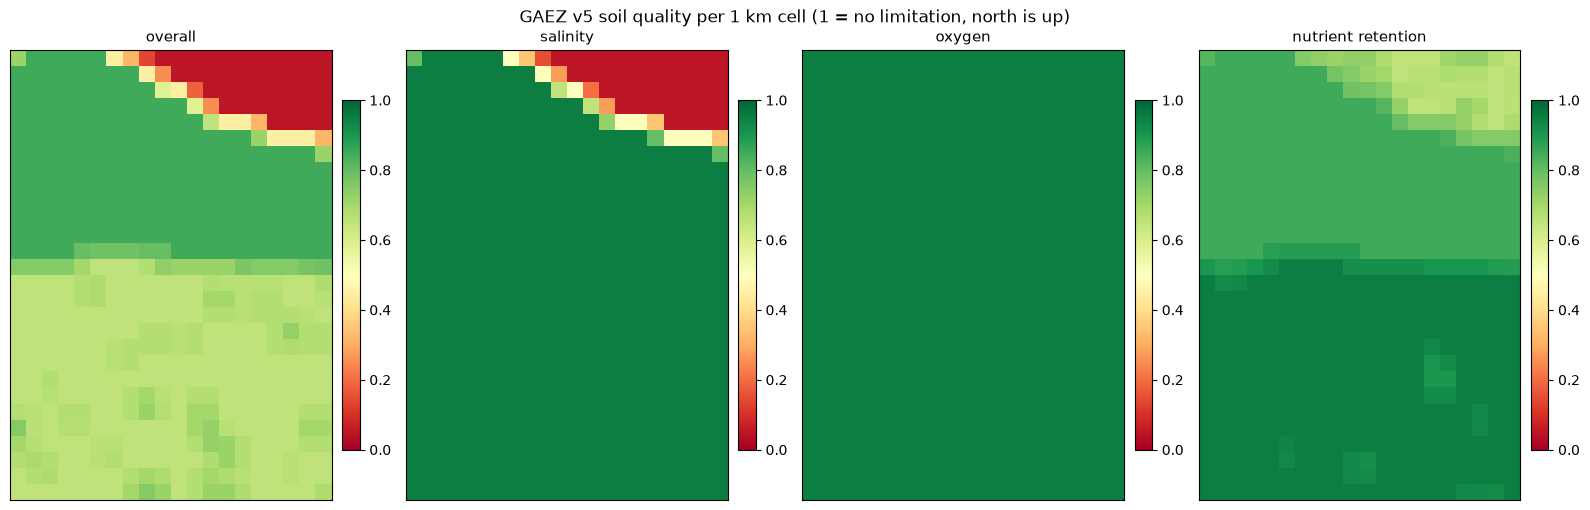

In [18]:
cols = ["soil_overall", "soil_salinity", "soil_oxygen", "soil_nutrient_retention"]
fig, axes = plt.subplots(1, 4, figsize=(16, 5.2))
for ax, c in zip(axes, cols):
    im = ax.imshow(to_map(out.set_index("cell_id")[c]), cmap="RdYlGn", vmin=0, vmax=1)
    ax.set_title(c.replace("soil_", "").replace("_", " "), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
fig.suptitle("GAEZ v5 soil quality per 1 km cell (1 = no limitation, north is up)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "06b_soil_maps.png", dpi=150)
plt.show()

## Step 5 - Does the soil show up in the crops?

GAEZ soil comes from the Harmonized World Soil Database, a soil map. Sentinel-2 knows nothing about soil maps - it only sees how green the fields are. If a soil problem is real and strong, cells where GAEZ rates that quality worse should tend to be **less green**. This is an independent check of the soil layer against the satellites.

We use the winter NDVI from notebook 08 and a rank (Spearman) correlation. A positive rho means "better soil, greener fields". We skip qualities that are the same in every cell, because a constant cannot correlate with anything.

We run up to 16 tests (8 qualities x 2 seasons), so about one would pass p < 0.05 by chance alone. As in notebook 08, we correct with the Benjamini-Hochberg false discovery rate and only call a link real if **q < 0.05**.

In [19]:
m = out.merge(sc[["cell_id", "winter_ndvi", "summer_ndvi", "is_farm_cell"]], on="cell_id")
m = m[m.is_farm_cell]
rows = []
for c in SQ.values():
    v = m[[c, "winter_ndvi", "summer_ndvi"]].dropna()
    if v[c].nunique() < 3:
        rows.append((c, v[c].nunique(), np.nan, np.nan, np.nan, np.nan)); continue
    rw = spearmanr(v[c], v.winter_ndvi); rs = spearmanr(v[c], v.summer_ndvi)
    rows.append((c, v[c].nunique(), rw.statistic, rw.pvalue, rs.statistic, rs.pvalue))
xc = pd.DataFrame(rows, columns=["quality", "distinct values", "rho winter", "p winter",
                                 "rho summer", "p summer"]).set_index("quality")
from scipy.stats import false_discovery_control
pv = pd.concat([xc["p winter"], xc["p summer"]]).dropna()
q  = pd.Series(false_discovery_control(pv.values, method="bh"), index=pv.index)
n_w = xc["p winter"].notna().sum()
xc.loc[xc["p winter"].notna(), "q winter"] = q.values[:n_w]
xc.loc[xc["p summer"].notna(), "q summer"] = q.values[n_w:]
print(f"farm cells used: {len(m)} | tests run: {len(pv)} (about {0.05*len(pv):.1f} expected below p = 0.05 by chance)")
print(xc[["distinct values", "rho winter", "q winter", "rho summer", "q summer"]].round(3).to_string())
sig = xc[(xc["q winter"] < 0.05) | (xc["q summer"] < 0.05)]
print(f"\nqualities linked to greenness after FDR correction (q < 0.05): {sig.index.tolist() or 'none'}")

farm cells used: 556 | tests run: 16 (about 0.8 expected below p = 0.05 by chance)
                         distinct values  rho winter  q winter  rho summer  q summer
quality                                                                             
soil_overall                          38      -0.124     0.011       0.089     0.083
soil_nutrients                        50       0.016     0.715      -0.205     0.000
soil_nutrient_retention               36       0.087     0.083      -0.188     0.000
soil_rooting                          12      -0.059     0.223       0.202     0.000
soil_oxygen                            3       0.061     0.223      -0.019     0.699
soil_salinity                         14       0.041     0.392      -0.060     0.223
soil_lime_gypsum                      24       0.040     0.392      -0.060     0.223
soil_workability                      38      -0.103     0.040       0.181     0.000

qualities linked to greenness after FDR correction (q < 0.05): ['s

### Reading the soil map correctly

The maps in Step 4 show that GAEZ soil is not a smooth measurement: it is made of **large blocks with straight edges** - the polygons of the Harmonized World Soil Database. Many neighbouring cells share exactly the same soil profile. That matters for the test above: 556 cells inside a few polygons are not 556 independent soil observations, so the p-values there are too optimistic.

We measure how blocky the layer is, then ask the one question that matters most for farming: are the cells GAEZ calls **saline** actually less productive?

In [ ]:
from scipy.stats import mannwhitneyu
q8 = list(SQ.values())
profile = out[q8].round(3).astype(str).agg("|".join, axis=1)
top3 = profile.value_counts().head(3)
print(f"distinct soil profiles (all 8 ratings together): {profile.nunique()}")
print(f"cells in the 3 most common profiles: {top3.tolist()} = {top3.sum() / len(out) * 100:.1f}% of the area")

mm = out.merge(sc[["cell_id", "winter_ndvi", "summer_ndvi", "farm_pct", "is_farm_cell"]], on="cell_id") \
        .merge(grid[["cell_id", "row", "col"]], on="cell_id")
mm = mm[mm.is_farm_cell]
sal = mm.soil_limit_name == "salinity and sodicity"
print(f"\nfarm cells where GAEZ names salinity as the main limit: {sal.sum()} "
      f"(rows {mm.loc[sal, 'row'].min()}-{mm.loc[sal, 'row'].max()}, cols {mm.loc[sal, 'col'].min()}-{mm.loc[sal, 'col'].max()}: the north-east corner)")
print(f"GAEZ salinity rating there: median {mm.loc[sal, 'soil_salinity'].median():.2f} (0 = severe)\n")
for c in ["winter_ndvi", "summer_ndvi", "farm_pct"]:
    a, b = mm.loc[sal, c], mm.loc[~sal, c]
    print(f"  {c:12s}: saline cells {a.median():.3f} | other cells {b.median():.3f} | Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.2g}")

distinct soil profiles (all 8 ratings together): 102
cells in the 3 most common profiles: [193, 42, 34] = 48.0% of the area

farm cells where GAEZ names salinity as the main limit: 47 (rows 1-6, cols 8-20: the north-east corner)
GAEZ salinity rating there: median 0.05 (0 = severe)

  winter_ndvi : saline cells 0.843 | other cells 0.840 | Mann-Whitney p = 0.23
  summer_ndvi : saline cells 0.741 | other cells 0.734 | Mann-Whitney p = 0.021
  farm_pct    : saline cells 0.958 | other cells 0.957 | Mann-Whitney p = 0.93


## Step 6 - Save

In [20]:
final_cols = (["cell_id"] + list(SQ.values()) + ["soil_water_share", "soil_limit_class", "soil_limit_name",
              "gaez_slope_flat_pct", "gaez_slope_lt2_pct", "gaez_slope_mean_pct"] +
              (["slope_srtm_mean_pct", "slope_srtm_max_pct"] if srtm is not None else []))
res = out[final_cols]

checks = {
    "560 rows, cell_id unique":  len(res) == 560 and res.cell_id.is_unique,
    "no column is all empty":    not res.isna().all().any(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values())
print(f"\n  SRTM slope included: {srtm is not None}")

res.to_csv(P / "soil_slope_static.csv", index=False)
print(f"saved soil_slope_static.csv {pd.read_csv(P / 'soil_slope_static.csv').shape}")
print("missing values per column:", res.isna().sum()[res.isna().sum() > 0].to_dict() or "none")

  PASS  560 rows, cell_id unique
  PASS  no column is all empty

  SRTM slope included: True
saved soil_slope_static.csv (560, 17)
missing values per column: none


## Conclusion

Every check passed, no column has a missing value, and the SRTM slope was computed on Earth Engine for all 560 cells. Every number below comes from the outputs above.

### 1. Slope: measured twice, and below what the data can resolve

| Source | Median cell slope |
|---|---|
| NASA SRTM, 30 m | 3.07% |
| GAEZ v5, ~1 km | 2.67% |

The two sources broadly agree (Spearman rho = +0.33). But the agreement is not proof that the slope is real, because GAEZ slope is also derived from an elevation model and shares its weaknesses. The elevation itself tells a different story:

- The whole area drops only **6.5 m over 28 km**. That is a regional slope of **0.023%**.
- The SRTM median cell slope is **133 times** larger than that.
- Inside a single 1 km cell, SRTM heights vary by a median of **9 m** - more than the whole area drops end to end.

That within-cell variation is not ground. SRTM measures the height of whatever the radar hits first: tree rows, houses, canal banks, plus its own measurement noise. A 3% slope between two neighbouring 30 m pixels is less than one metre of height difference (0.92 m), well inside that noise. Slope is also slightly higher where there is less farmland (rho = -0.15), which is what surface objects would produce.

**Result:** the true field slope in our area is too small for these datasets to measure. The land is flat. **Slope will not be used to rank crops.** We keep the columns for transparency.

### 2. Soil: what GAEZ says

| Quality | Median rating (1 = no limit) | Range across cells |
|---|---|---|
| Overall (worst of all) | 0.68 | 0.05-0.85 |
| Workability | 0.72 | 0.65-0.95 |
| Nutrients | 0.78 | 0.45-0.85 |
| Rooting | 0.85 | 0.85-0.95 |
| Nutrient retention | 0.92 | 0.65-0.95 |
| Oxygen / drainage | 0.95 | 0.95-0.95 |
| Salinity | 0.95 | **0.05**-0.95 |
| Lime and gypsum | 0.95 | 0.72-0.95 |

The **main** soil limit in each cell:

| Main limit | Cells |
|---|---|
| Workability | 257 |
| No or slight constraints | 252 |
| **Salinity and sodicity** | **47** |
| Water | 2 |
| No information | 2 |

Drainage is not a limit anywhere (0.95 in every cell). Salinity is not a problem in most of the area, but where GAEZ says it is, it says it is **severe**: a rating of 0.05 in the north-east corner.

### 3. Soil: what the satellites say about it

**The soil layer is a map of a few large blocks, not a measurement of each field.** The 560 cells hold 102 distinct soil profiles, but the 3 most common ones cover **48%** of the area, and the maps show straight polygon edges. Many cells are copies of each other.

That is why the test linking soil to greenness must be read carefully. Five qualities passed the false discovery rate correction, but the links are weak (|rho| at most 0.21), and **their direction flips between seasons**: workability goes with *less* green fields in winter (rho = -0.10) and *greener* fields in summer (rho = +0.18). A real soil effect would not reverse with the season. With so many cells copied from the same polygon, the p-values overstate how much independent evidence there is.

**The salinity check is the clearest result.** The 47 farm cells GAEZ calls severely saline are **just as productive** as the rest:

| | Saline cells | Other cells | p (Mann-Whitney) |
|---|---|---|---|
| Winter NDVI | 0.843 | 0.840 | 0.23 |
| Summer NDVI | 0.741 | 0.734 | 0.021 |
| Share farmed | 0.958 | 0.957 | 0.93 |

If anything, the "saline" cells are slightly *greener* in summer. Salt damage would show up as weaker crops. It does not. Either farmers there manage the salt successfully, or the soil map no longer describes those fields. Our data cannot tell which.

### What notebook 10 does with this

| Finding | Use in scoring |
|---|---|
| Slope is below the data's resolution | **not used** |
| Soil differences do not show up in crop vigour | soil is **not** used to push one cell above another |
| 47 cells flagged saline by the soil map | the tool shows a **"check your soil before choosing"** note there, instead of silently lowering the score |
| GAEZ suitability (notebook 06) already includes soil, crop by crop | soil reaches the score only through that, where it is crop-specific |

We added this notebook because the plan asked for slope and soil. The honest answer is that in this flat, long-irrigated area **neither one changes which crop fits a field** - and we can show why, with numbers, instead of assuming it.
